# Phase 1: Dataset Understanding

The objective of this phase is to explore and understand the product review dataset before building the spam detection model.

We will inspect the dataset structure, label distribution, missing values, and duplicate records to identify potential data quality issues.

### Step 1.1: Import Libraries and Load Dataset

Import the required libraries and load the original dataset into a Pandas DataFrame for analysis.

In [1]:
# 1. General Libraries
import os
import re
import html
import string
import warnings

# 2. Data Processing
import numpy as np
import pandas as pd

# 3. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. NLP Preprocessing
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# 5. Feature Extraction
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 6. Train-Test Split and Cross-Validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# 7. Machine Learning Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 8. Model Pipeline
from sklearn.pipeline import Pipeline

# 9. Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    make_scorer
)

# 10. Save and Load Models
import joblib

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the original dataset
df = pd.read_csv("../dataset/original_dataset.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five rows
display(df.head())

Dataset loaded successfully!
Dataset shape: (40432, 4)


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


### Step 1.2: Inspect Dataset Structure

Examine the dataset's columns, data types, and label distribution to understand the available information and classification target.

In [3]:
# Display column names
print("Dataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display original label distribution
print("\nOriginal Label Distribution:")
print(df["label"].value_counts())

# Display label percentages
print("\nLabel Distribution (%):")
print((df["label"].value_counts(normalize=True) * 100).round(2))

Dataset Columns:
['category', 'rating', 'label', 'text_']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  str    
 1   rating    40432 non-null  float64
 2   label     40432 non-null  str    
 3   text_     40432 non-null  str    
dtypes: float64(1), str(3)
memory usage: 15.5 MB

Original Label Distribution:
label
CG    20216
OR    20216
Name: count, dtype: int64

Label Distribution (%):
label
CG    50.0
OR    50.0
Name: proportion, dtype: float64


### Step 1.3: Check Missing Values and Duplicate Records

Check for missing values and duplicate records to identify potential data quality issues before preprocessing.

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# Check duplicate review texts
print("\nNumber of Duplicate Review Texts:")
print(df["text_"].duplicated().sum())

Missing Values:
category    0
rating      0
label       0
text_       0
dtype: int64

Number of Duplicate Rows:
12

Number of Duplicate Review Texts:
20


Interpretation:
- No missing values were found.
- 12 complete duplicate rows were identified.
- 20 duplicate review texts were found.
- Some identical reviews might have different labels or metadata, so we should investigate before removing them.

### Step 1.4: Investigate Duplicate Reviews

Examine duplicate review texts to determine whether identical reviews have consistent labels. This helps prevent incorrect data removal and potential label conflicts.

In [5]:
# Extract reviews with duplicate text
duplicate_texts = df[df["text_"].duplicated(keep=False)].sort_values("text_")

# Display duplicate reviews and their labels
display(duplicate_texts[["text_", "label", "category", "rating"]])

# Count unique labels for each duplicated review text
label_counts = duplicate_texts.groupby("text_")["label"].nunique()

# Identify reviews with conflicting labels
conflicting_texts = label_counts[label_counts > 1]

print("Number of duplicated review texts:", len(label_counts))
print("Number of conflicting review texts:", len(conflicting_texts))

,text_,label,category,rating
143,Easy to put together and looks nice and the fi...,CG,Home_and_Kitchen_5,5.0
725,Easy to put together and looks nice and the fi...,CG,Home_and_Kitchen_5,4.0
22294,Got these to give to my 8 mth old chihuahua wh...,OR,Pet_Supplies_5,5.0
22305,Got these to give to my 8 mth old chihuahua wh...,OR,Pet_Supplies_5,5.0
6706,"Great, no complaints. Comfortable, phone fits ...",CG,Sports_and_Outdoors_5,5.0
6708,"Great, no complaints. Comfortable, phone fits ...",CG,Sports_and_Outdoors_5,5.0
38801,I bought these for my daughter. She loves them...,CG,Clothing_Shoes_and_Jewelry_5,5.0
38808,I bought these for my daughter. She loves them...,CG,Clothing_Shoes_and_Jewelry_5,4.0
37296,I bought this for a Halloween costume and it w...,CG,Clothing_Shoes_and_Jewelry_5,5.0
37543,I bought this for a Halloween costume and it w...,CG,Clothing_Shoes_and_Jewelry_5,5.0


Number of duplicated review texts: 20
Number of conflicting review texts: 0


Interpretation:
- 20 duplicated review texts were identified.
- None have conflicting labels (CG and OR).
- All duplicated texts share the same classification label.
- Some duplicates have different ratings, but the classification target remains consistent.

Decision: We can remove exact duplicate rows, but we don't automatically remove all repeated review texts. Because they may contain different ratings or represent separate records. We'll handle duplicate-text leakage carefully when splitting the dataset.

### Step 1.5: Remove Exact Duplicate Rows

Remove identical records to avoid unnecessary repetition while preserving reviews that have the same text but different metadata.

In [6]:
# Record dataset size before removing duplicates
before = len(df)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Record dataset size after removing duplicates
after = len(df)

# Display cleaning summary
print("Rows before:", before)
print("Rows after:", after)
print("Duplicate rows removed:", before - after)

Rows before: 40432
Rows after: 40420
Duplicate rows removed: 12


### Step 1.6: Map Labels to Numerical Values

Convert the original labels into numerical values for binary classification.

- `CG` → `1` (Spam)
- `OR` → `0` (Non-Spam)

In [7]:
# Map original labels to numerical values
label_mapping = {
    "CG": 1,  # Spam
    "OR": 0   # Non-Spam
}

df["target"] = df["label"].map(label_mapping)

# Display label mapping
print("Label Mapping:")
display(df[["label", "target"]].drop_duplicates())

# Check the updated class distribution
print("\nTarget Distribution:")
print(df["target"].value_counts().sort_index())

# Check for unmapped labels
print("\nMissing Target Values:", df["target"].isnull().sum())

Label Mapping:


,label,target
0,CG,1
55,OR,0



Target Distribution:
target
0    20215
1    20205
Name: count, dtype: int64

Missing Target Values: 0


## Phase 1: Dataset Understanding Summary

| Item | Result |
|---|---:|
| Original records | 40,432 |
| Records after removing exact duplicates | 40,420 |
| Missing values | 0 |
| Exact duplicate rows removed | 12 |
| Repeated review texts | 20 |
| Conflicting duplicate labels | 0 |
| Spam (CG = 1) | 20,205 |
| Non-Spam (OR = 0) | 20,215 |

**Conclusion:** The dataset contains 40,420 records with no missing values. Both classes are almost perfectly balanced, making the dataset suitable for binary classification without additional class balancing.

# Phase 2: Exploratory Data Analysis (EDA)

The objective of this phase is to explore the characteristics and patterns of the review dataset.

We will examine class distribution, review length, rating distribution, and product categories to better understand the data before text preprocessing.

### Step 2.1: Analyze Review Text Length

Examine the length of Spam and Non-Spam reviews to identify differences in their writing patterns.

We will calculate the number of characters and words in each review and compare their distributions.

In [8]:
# Calculate review length by characters and words
df["char_count"] = df["text_"].str.len()
df["word_count"] = df["text_"].str.split().str.len()

# Compare text length between classes
text_length_summary = df.groupby("target")[["char_count", "word_count"]].describe()
# Calculate review length statistics by class
char_summary = df.groupby("target")["char_count"].agg(
    ["count", "mean", "std", "min", "median", "max"]
).round(2)

word_summary = df.groupby("target")["word_count"].agg(
    ["count", "mean", "std", "min", "median", "max"]
).round(2)

# Rename class labels for readability
char_summary.index = ["Non-Spam", "Spam"]
word_summary.index = ["Non-Spam", "Spam"]

# Display separate summary tables
print("Review Character Count Summary")
display(char_summary)

print("Review Word Count Summary")
display(word_summary)

Review Character Count Summary


,count,mean,std,min,median,max
Non-Spam,20215,396.97,418.44,28,224.0,2827
Spam,20205,305.65,307.09,24,174.0,1717


Review Word Count Summary


,count,mean,std,min,median,max
Non-Spam,20215,73.64,76.08,5,42.0,373
Spam,20205,61.30,61.81,1,35.0,318


Interpretation
- Non-Spam reviews are generally longer than Spam reviews.
- Average character count: Non-Spam (396.97) vs. Spam (305.65).
- Average word count: Non-Spam (73.64) vs. Spam (61.30).
- The median values show the same pattern, suggesting this difference is not caused only by a few unusually long reviews.

### Step 2.2: Visualize Review Length Distribution

Visualize the character and word count distributions of Spam and Non-Spam reviews to compare their writing lengths and identify potential differences.

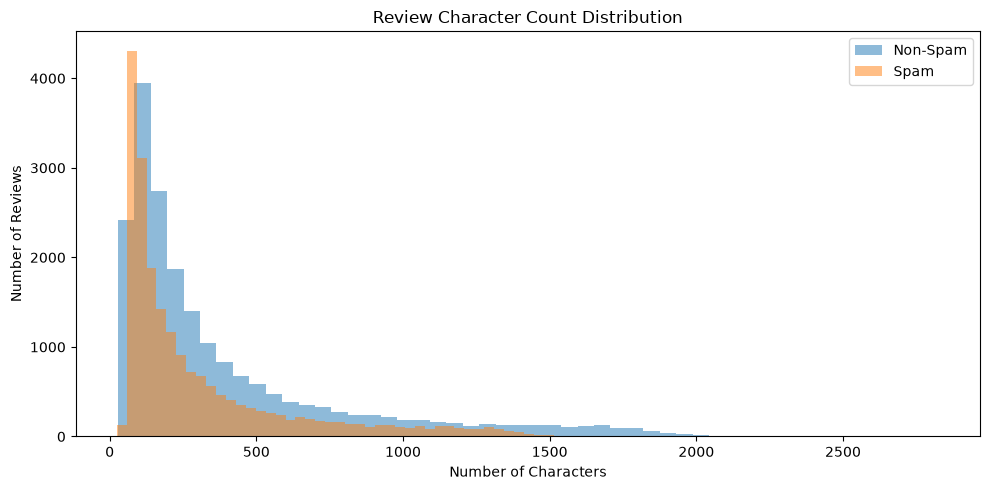

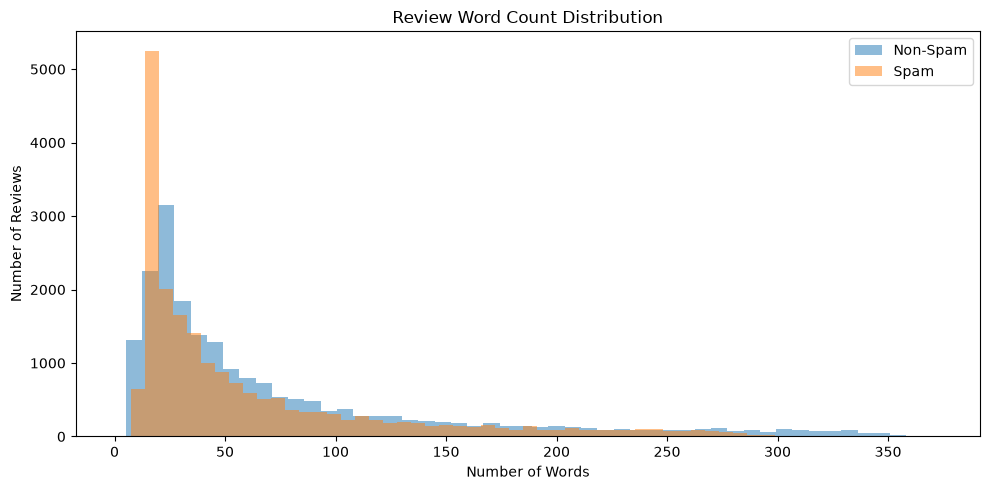

In [9]:
# Compare character count distributions
plt.figure(figsize=(10, 5))

for target, label in [(0, "Non-Spam"), (1, "Spam")]:
    plt.hist(
        df[df["target"] == target]["char_count"],
        bins=50,
        alpha=0.5,
        label=label
    )

plt.title("Review Character Count Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")
plt.legend()
plt.tight_layout()
plt.show()


# Compare word count distributions
plt.figure(figsize=(10, 5))

for target, label in [(0, "Non-Spam"), (1, "Spam")]:
    plt.hist(
        df[df["target"] == target]["word_count"],
        bins=50,
        alpha=0.5,
        label=label
    )

plt.title("Review Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.legend()
plt.tight_layout()
plt.show()

### Step 2.3: Analyze Rating Distribution

Examine the distribution of product ratings across Spam and Non-Spam reviews to identify potential differences in rating patterns.

In [10]:
# Calculate rating distribution by review class
rating_summary = pd.crosstab(
    df["rating"],
    df["target"],
    normalize="columns"
).mul(100).round(2)

rating_summary.columns = ["Non-Spam (%)", "Spam (%)"]

print("Rating Distribution by Review Class (%)")
display(rating_summary)

Rating Distribution by Review Class (%)


,Non-Spam (%),Spam (%)
rating,,
1.0,5.40,5.26
2.0,4.97,4.76
3.0,9.07,9.66
4.0,20.01,19.40
5.0,60.54,60.92


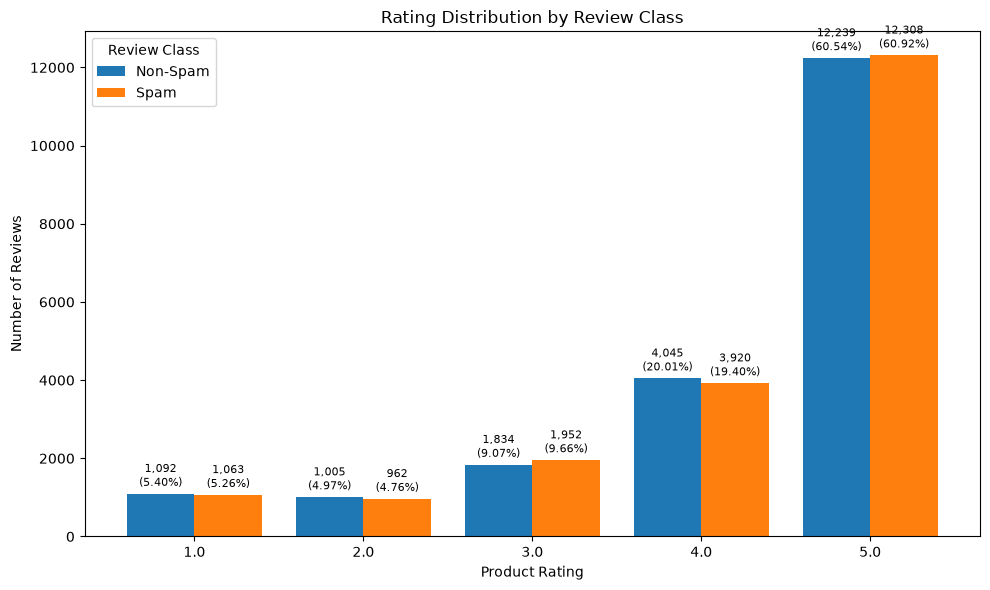

In [11]:
# Calculate rating counts
rating_counts = pd.crosstab(df["rating"], df["target"])
rating_counts.columns = ["Non-Spam", "Spam"]

# Calculate percentages within each review class
rating_percentages = pd.crosstab(
    df["rating"],
    df["target"],
    normalize="columns"
) * 100

rating_percentages.columns = ["Non-Spam", "Spam"]

# Create grouped bar chart
ax = rating_counts.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

# Add count and percentage labels
for i, container in enumerate(ax.containers):
    class_name = ["Non-Spam", "Spam"][i]

    for j, bar in enumerate(container):
        count = int(bar.get_height())
        percentage = rating_percentages.iloc[j][class_name]

        ax.annotate(
            f"{count:,}\n({percentage:.2f}%)",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

# Chart formatting
ax.set_title("Rating Distribution by Review Class")
ax.set_xlabel("Product Rating")
ax.set_ylabel("Number of Reviews")
ax.set_xticklabels(rating_counts.index, rotation=0)
ax.legend(title="Review Class")

plt.tight_layout()
plt.show()

**Finding:**

Both Spam and Non-Spam reviews show very similar rating distributions, with 5-star ratings being the most common in both classes. The average ratings are nearly identical. Therefore, product ratings alone may not be useful for distinguishing computer-generated reviews from original reviews. The classification model should focus primarily on textual features.

### Step 2.4: Analyze Product Category Distribution

Examine the distribution of Spam and Non-Spam reviews across product categories to identify whether certain product categories have different proportions of computer-generated and original reviews.

In [12]:
# Calculate review counts by category and class
category_counts = pd.crosstab(
    df["category"],
    df["target"]
)

category_counts.columns = ["Non-Spam", "Spam"]

# Calculate percentages within each category
category_percentages = pd.crosstab(
    df["category"],
    df["target"],
    normalize="index"
).mul(100).round(2)

category_percentages.columns = ["Non-Spam", "Spam"]

# Combine counts and percentages into one table
category_results = pd.DataFrame(index=category_counts.index)

category_results["Non-Spam (Count)"] = category_counts["Non-Spam"]
category_results["Non-Spam (%)"] = category_percentages["Non-Spam"]

category_results["Spam (Count)"] = category_counts["Spam"]
category_results["Spam (%)"] = category_percentages["Spam"]

# Display combined results
print("Review Distribution by Product Category:")
print(category_results.to_string())

Review Distribution by Product Category:
                              Non-Spam (Count)  Non-Spam (%)  Spam (Count)  Spam (%)
category                                                                            
Books_5                                   2185         50.01          2184     49.99
Clothing_Shoes_and_Jewelry_5              1924         50.01          1923     49.99
Electronics_5                             1994         50.00          1994     50.00
Home_and_Kitchen_5                        2028         50.00          2028     50.00
Kindle_Store_5                            2365         50.02          2363     49.98
Movies_and_TV_5                           1794         50.01          1793     49.99
Pet_Supplies_5                            2126         50.01          2125     49.99
Sports_and_Outdoors_5                     1973         50.03          1971     49.97
Tools_and_Home_Improvement_5              1929         50.00          1929     50.00
Toys_and_Games_5        

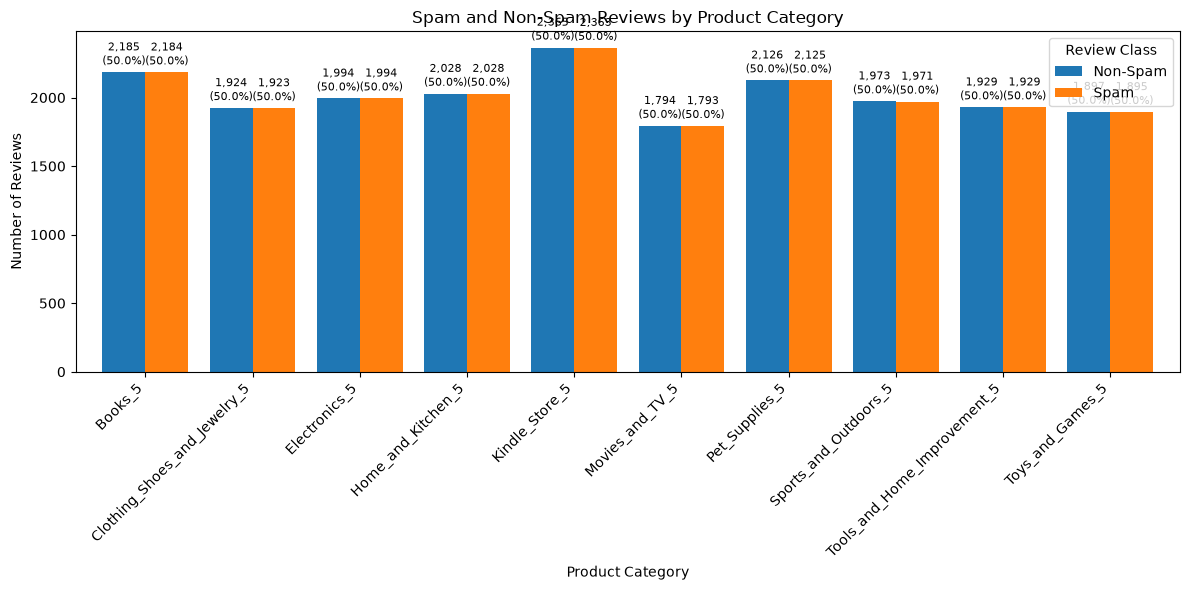

In [13]:
# Create grouped bar chart
ax = category_counts.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

# Add count and percentage labels
for i, container in enumerate(ax.containers):
    class_name = ["Non-Spam", "Spam"][i]

    for j, bar in enumerate(container):
        count = int(bar.get_height())
        percentage = category_percentages.iloc[j, i]

        ax.annotate(
            f"{count:,}\n({percentage:.1f}%)",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

# Format chart
ax.set_title("Spam and Non-Spam Reviews by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Number of Reviews")
ax.set_xticklabels(category_counts.index, rotation=45, ha="right")
ax.legend(title="Review Class")

plt.tight_layout()
plt.show()

Interpretation
- The dataset contains 10 product categories.
- Every category has an almost equal proportion of Spam and Non-Spam reviews.
- No product category shows a noticeable class imbalance.

### Step 2.5: Examine Sample Reviews

Inspect sample Spam and Non-Spam reviews to understand their writing styles, wording, and potential textual differences before preprocessing.

In [14]:
# Set Pandas to display complete text
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

# Display five Spam reviews
print("Sample Spam Reviews:")
display(
    df[df["target"] == 1][["text_", "label"]].sample(
        5, random_state=42
    )
)

# Display five Non-Spam reviews
print("\nSample Non-Spam Reviews:")
display(
    df[df["target"] == 0][["text_", "label"]].sample(
        5, random_state=42
    )
)

Sample Spam Reviews:


,text_,label
4600,"While this mattress was easy to assemble, the materials are thick enough to make it comfortable to sleep in",CG
8386,It seems like the glass is a little too thick. I will admit that it's been a little,CG
31719,"""Sway"" is a book that helps me understand the relationship between two women. It's a book that is so heart-warming.\n\nI have to say, I was very impressed by this book. It was written in a very enjoyable style. I found it very easy to read. I was also impressed by the way the author made it clear that her husband was a good friend and mentor to her. I'm sure she was very generous to both of her children and to her husband.\n\nI have a feeling that readers of this book will enjoy it very much. I am looking forward",CG
8660,Loved this case! It looks great and the materials are good. I have a few,CG
224,I like the clock although it has the design flaw which is that it is a little hard to read,CG



Sample Non-Spam Reviews:


,text_,label
22271,"This ball and squeeker has outlasted all the other squeaky dog toys, including the hippo kong, kyjen Platypus plush squeaky eggs. The Kyjen Invicibles Plush Snake Stuffingless dog toy is still squeaking and in pretty good shape, the pup detached some trim but couldn't figure out how to tear it up. She shreaded her Kong Ballistic Ring dog toy in nothing flat, sadly.",OR
25770,"The premise of the course was quite romantic and as a result the reader conjures imagines of the novel should be. This book at times felt like a noble from the nineteen century. Also it promised hot steamy sex, don't waste your money it contained none.",OR
21804,Puppy loves this donkey. She's a bit aggressive with it. I've had to stitch part of the neck back up. The sound box works great. No sign of her being able to remove it. I would buy this again if he meets his demise since he's her favorite.,OR
5227,Mine came brand new practically. It's so warm with all them put together perfect sleeping bag should last a life time if stored well.,OR
18346,"Cuts perfect and last for an extremely long time. We use Freud exclusively in our shop. Best blades on the market. Only thing I would change would be to make them without the red paint. It sometimes transfers to the material that is being cut and has to be sanded off. On the other hand, the red blades look cool. This 40 tooth cuts better than other brands with 90+ tooth blades.",OR


**Finding:**

Sample reviews show differences in writing patterns, with some Non-Spam reviews containing more specific product experiences and personal details. However, Spam reviews can also appear natural and descriptive. Both classes share similar language patterns, making simple keyword-based classification unreliable. Text preprocessing and feature extraction will be important for identifying more meaningful patterns.

## Phase 2: Exploratory Data Analysis Summary

| Analysis | Key Finding |
|---|---|
| Review Length | Non-Spam reviews are generally longer than Spam reviews. |
| Rating Distribution | Both classes have nearly identical rating patterns and average ratings. |
| Product Categories | All 10 categories have approximately 50% Spam and 50% Non-Spam reviews. |
| Sample Reviews | Both classes share similar writing patterns, making classification challenging. |

**Conclusion:** Review length shows some differences between the two classes, while ratings and product categories provide limited distinguishing information. Therefore, the project will focus primarily on textual features for classification.

# Phase 3: Text Preprocessing

The objective of this phase is to clean and normalize review text before feature extraction. We will inspect text quality, apply appropriate cleaning techniques, and prepare a consistent text column for classification.

### Step 3.1: Inspect Text Quality

Inspect sample reviews and identify common text patterns before applying preprocessing techniques. This helps us decide what needs to be cleaned without removing useful information.

In [15]:
# Inspect common text patterns
print("Sample Review Texts:")
for i, text in enumerate(df["text_"].sample(10, random_state=42), 1):
    print(f"\nReview {i}:")
    print(repr(text[:500]))

# Check for common text patterns
text_quality = {
    "Empty Reviews": df["text_"].str.strip().eq("").sum(),
    "HTML Entities": df["text_"].str.contains(
        r"&[a-zA-Z]+;|&#\d+;", regex=True
    ).sum(),
    "URLs": df["text_"].str.contains(
        r"https?://|www\.", case=False, regex=True
    ).sum(),
    "Extra Whitespace": df["text_"].str.contains(
        r"\s{2,}", regex=True
    ).sum(),
    "Digits": df["text_"].str.contains(
        r"\d", regex=True
    ).sum()
}

print("\nText Quality Inspection:")
display(pd.DataFrame.from_dict(
    text_quality, orient="index", columns=["Number of Reviews"]
))

Sample Review Texts:

Review 1:
"Well made hat.  Soft and comfortable.  Great quality.  Also, it's been used to wash my hands.  I am very happy"

Review 2:
'and many different uses (I use this as a gate quite often) to separate my senior dog and my puppy.  I have also put it outside for the puppy, or to separate them while they eat.\ngreat quality, cute color for two girl dogs.  great price, and arrived right on time.'

Review 3:
'Big hit with my 3 year old granddaughter.  Her dad is a big fan of this game.'

Review 4:
"Did nothing. Still combing huge hay. The only problem is that it's kind of hard to find."

Review 5:
'A wonderful read.  I was sad when the story ended.  Nora Roberts never fails to bring you back!'

Review 6:
"My cat loves this, and Id also like to add when using his litter box the smell has decreased. I will cont to purchase this product as well as other natural balance products for him.\nI was having a hard time finding a dry food as well as a wet food he preferred, 

,Number of Reviews
Empty Reviews,0
HTML Entities,167
URLs,109
Extra Whitespace,20302
Digits,11001


**Finding:**

The dataset contains no empty reviews, but some reviews include HTML entities, URLs, and extra whitespace. Numbers are also common in the review text. These patterns indicate that text normalization is needed. However, numbers and meaningful punctuation should be preserved where possible to avoid losing useful information.

### Step 3.2: Inspect HTML Entities and URLs

Examine examples of HTML entities and URLs to determine how they should be handled during text preprocessing.

In [16]:
# Find reviews containing HTML entities
html_reviews = df[
    df["text_"].str.contains(
        r"&[a-zA-Z]+;|&#\d+;", regex=True
    )
]

# Find reviews containing URLs
url_reviews = df[
    df["text_"].str.contains(
        r"https?://|www\.", case=False, regex=True
    )
]

print("Examples of Reviews Containing HTML Entities:")
for text in html_reviews["text_"].head(5):
    print("-", repr(text[:300]))

print("\nExamples of Reviews Containing URLs:")
for text in url_reviews["text_"].head(5):
    print("-", repr(text[:300]))

Examples of Reviews Containing HTML Entities:
- '<a data-hook="product-link-linked" class="a-link-normal" href="/ORBLUE-Flatware-Pie-Server-Stainless-Steel-Cake-Cutter/dp/B011J5MKPC/ref=cm_cr_arp_d_rvw_txt?ie=UTF8">ORBLUE Flatware Pie Server Stainless Steel Cake Cutter</a>&nbsp;FOR REVIEW\n\nGREAT QUALITY. nice finish good and solid item feels and l'
- '<div id="video-block-R37QTX6O7Y959J" class="a-section a-spacing-small a-spacing-top-mini video-block"></div><input type="hidden" name="" value="https://images-na.ssl-images-amazon.com/images/I/B1xegDi61NS.mp4" class="video-url"><input type="hidden" name="" value="https://images-na.ssl-images-amazon.'
- '<div id="video-block-RCLJDSSDKWYNA" class="a-section a-spacing-small a-spacing-top-mini video-block"></div><input type="hidden" name="" value="https://images-na.ssl-images-amazon.com/images/I/B1PIAjQWaWS.mp4" class="video-url"><input type="hidden" name="" value="https://images-na.ssl-images-amazon.c'
- 'Apparently, from the reviews and i

For preprocessing, we should:
- Remove HTML tags and embedded HTML content.
- Decode HTML entities such as &nbsp;.
- Remove URLs because the links themselves are unlikely to help classify review writing.
- Preserve the actual review sentences.

### Step 3.3: Remove HTML Content and URLs

Remove HTML tags, decode HTML entities, and remove URLs from review text. Preserve the remaining review content for further preprocessing.

In [17]:
import re
import html

# Define a function to clean HTML content and URLs
def clean_html_urls(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Normalize extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning to review text
df["clean_text"] = df["text_"].apply(clean_html_urls)

# Compare original and cleaned reviews
comparison = df[["text_", "clean_text"]].head(5)

display(comparison)

,text_,clean_text
0,"Love this! Well made, sturdy, and very comfortable. I love it!Very pretty","Love this! Well made, sturdy, and very comfortable. I love it!Very pretty"
1,"love it, a great upgrade from the original. I've had mine for a couple of years","love it, a great upgrade from the original. I've had mine for a couple of years"
2,This pillow saved my back. I love the look and feel of this pillow.,This pillow saved my back. I love the look and feel of this pillow.
3,"Missing information on how to use it, but it is a great product for the price! I","Missing information on how to use it, but it is a great product for the price! I"
4,Very nice set. Good quality. We have had the set for two months now and have not been,Very nice set. Good quality. We have had the set for two months now and have not been


**Finding:**

HTML tags, HTML entities, and URLs are handled during text cleaning. Extra whitespace is also normalized. The original review text is preserved in the `text_` column, while the cleaned version is stored separately in `clean_text` for further processing.

### Step 3.4: Convert Text to Lowercase

Convert all cleaned reviews to lowercase to ensure consistent word representation during feature extraction.

In [18]:
# Convert cleaned review text to lowercase
df["clean_text"] = df["clean_text"].str.lower()

# Compare original and lowercase text
display(df[["text_", "clean_text"]].head(5))

,text_,clean_text
0,"Love this! Well made, sturdy, and very comfortable. I love it!Very pretty","love this! well made, sturdy, and very comfortable. i love it!very pretty"
1,"love it, a great upgrade from the original. I've had mine for a couple of years","love it, a great upgrade from the original. i've had mine for a couple of years"
2,This pillow saved my back. I love the look and feel of this pillow.,this pillow saved my back. i love the look and feel of this pillow.
3,"Missing information on how to use it, but it is a great product for the price! I","missing information on how to use it, but it is a great product for the price! i"
4,Very nice set. Good quality. We have had the set for two months now and have not been,very nice set. good quality. we have had the set for two months now and have not been


**Finding:**

All cleaned reviews have been converted to lowercase to ensure consistent word representation. This prevents words with different capitalization from being treated as separate features during text vectorization.

### Step 3.5: Verify Whitespace Normalization

Check whether repeated whitespace remains in the cleaned review text after preprocessing.

In [19]:
# Count reviews containing repeated whitespace
remaining_whitespace = df["clean_text"].str.contains(
    r"\s{2,}", regex=True
).sum()

print("Reviews with extra whitespace:", remaining_whitespace)

Reviews with extra whitespace: 0


**Finding:**

All repeated whitespace has been successfully normalized. No reviews contain extra whitespace after cleaning, ensuring consistent text formatting.

### Step 3.6: Inspect Punctuation and Numbers

Examine punctuation and numerical patterns in the cleaned reviews to determine whether they should be preserved during preprocessing.

In [20]:
# Count reviews containing punctuation
punctuation_count = df["clean_text"].str.contains(
    r"[^\w\s]", regex=True
).sum()

# Count reviews containing digits
digit_count = df["clean_text"].str.contains(
    r"\d", regex=True
).sum()

print("Reviews containing punctuation:", punctuation_count)
print("Reviews containing digits:", digit_count)

# Display examples
print("\nExamples containing punctuation:")
display(df[df["clean_text"].str.contains(
    r"[^\w\s]", regex=True
)][["clean_text"]].head(5))

print("\nExamples containing digits:")
display(df[df["clean_text"].str.contains(
    r"\d", regex=True
)][["clean_text"]].head(5))

Reviews containing punctuation: 40041
Reviews containing digits: 10940

Examples containing punctuation:


,clean_text
0,"love this! well made, sturdy, and very comfortable. i love it!very pretty"
1,"love it, a great upgrade from the original. i've had mine for a couple of years"
2,this pillow saved my back. i love the look and feel of this pillow.
3,"missing information on how to use it, but it is a great product for the price! i"
4,very nice set. good quality. we have had the set for two months now and have not been



Examples containing digits:


,clean_text
10,as advertised. 5th one i've had. the only problem is that it's not really a
12,"did someone say, ""oriental for $60""? it is a great product for the"
19,"10 stars, i would highly recommend this item. we love this blanket."
26,not what i am accustomed to. the only reason i gave it 4 stars is because i just can
35,way too heavy for everyday use. the only reason i gave it 4 stars is because the one we


**Finding:**

Most reviews contain punctuation, while many also contain numerical information. Both are preserved because they may provide useful textual patterns for distinguishing computer-generated reviews from original reviews.

### Step 3.7: Validate Cleaned Text

Verify that the main unwanted HTML content, URLs, and repeated whitespace have been removed from the cleaned review text.

In [21]:
# Validate cleaned text
validation_results = {
    "HTML Tags": df["clean_text"].str.contains(
        r"<[^>]+>", regex=True
    ).sum(),
    "URLs": df["clean_text"].str.contains(
        r"https?://|www\.", case=False, regex=True
    ).sum(),
    "Extra Whitespace": df["clean_text"].str.contains(
        r"\s{2,}", regex=True
    ).sum(),
    "Empty Reviews": df["clean_text"].str.strip().eq("").sum()
}

print("Cleaned Text Validation:")
display(pd.DataFrame.from_dict(
    validation_results,
    orient="index",
    columns=["Remaining Reviews"]
))

Cleaned Text Validation:


,Remaining Reviews
HTML Tags,0
URLs,1
Extra Whitespace,0
Empty Reviews,0


### Step 3.8: Inspect Remaining URL

Inspect the remaining review containing a URL to understand why it was not removed during the initial cleaning step.

In [22]:
import re
import html

def clean_html_urls(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove URLs, including URLs containing spaces after www.
    text = re.sub(
        r"https?://\S+|www\.\s*\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Normalize extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Recreate cleaned text from original text
df["clean_text"] = df["text_"].apply(clean_html_urls)

# Convert to lowercase
df["clean_text"] = df["clean_text"].str.lower()

# Validate URL removal
remaining_urls = df["clean_text"].str.contains(
    r"https?://|www\.",
    case=False,
    regex=True
).sum()

print("Remaining reviews containing URLs:", remaining_urls)

Remaining reviews containing URLs: 0


**Finding:**

The URL removal pattern was improved to handle URLs containing spaces after `www.`. The updated cleaning function successfully removed all remaining URLs while retaining the review text.

### Step 3.9: Tokenization

Use NLTK to split each cleaned review into individual word tokens. This prepares the text for further NLP preprocessing and feature extraction.

In [23]:
import nltk
from nltk.tokenize import word_tokenize

# Download the tokenizer resource
nltk.download("punkt")
nltk.download("punkt_tab")

# Tokenize cleaned reviews
df["tokens"] = df["clean_text"].apply(word_tokenize)

# Display original cleaned text and tokens
display(df[["clean_text", "tokens"]].head(5))

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\TRC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\TRC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,clean_text,tokens
0,"love this! well made, sturdy, and very comfortable. i love it!very pretty","[love, this, !, well, made, ,, sturdy, ,, and, very, comfortable, ., i, love, it, !, very, pretty]"
1,"love it, a great upgrade from the original. i've had mine for a couple of years","[love, it, ,, a, great, upgrade, from, the, original, ., i, 've, had, mine, for, a, couple, of, years]"
2,this pillow saved my back. i love the look and feel of this pillow.,"[this, pillow, saved, my, back, ., i, love, the, look, and, feel, of, this, pillow, .]"
3,"missing information on how to use it, but it is a great product for the price! i","[missing, information, on, how, to, use, it, ,, but, it, is, a, great, product, for, the, price, !, i]"
4,very nice set. good quality. we have had the set for two months now and have not been,"[very, nice, set, ., good, quality, ., we, have, had, the, set, for, two, months, now, and, have, not, been]"


### Step 3.10: Remove Stopwords

Remove common English stopwords using NLTK while preserving important negation words such as `not`, `no`, and `never`, which may carry useful information for review classification.

In [24]:
from nltk.corpus import stopwords

# Download English stopwords
nltk.download("stopwords")

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Preserve important negation words
negation_words = {"no", "nor", "not", "never"}

stop_words = stop_words - negation_words

# Remove stopwords from tokenized reviews
df["filtered_tokens"] = df["tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word not in stop_words
    ]
)

# Compare tokens before and after stopword removal
display(
    df[["tokens", "filtered_tokens"]].head(5)
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\TRC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,tokens,filtered_tokens
0,"[love, this, !, well, made, ,, sturdy, ,, and, very, comfortable, ., i, love, it, !, very, pretty]","[love, !, well, made, ,, sturdy, ,, comfortable, ., love, !, pretty]"
1,"[love, it, ,, a, great, upgrade, from, the, original, ., i, 've, had, mine, for, a, couple, of, years]","[love, ,, great, upgrade, original, ., 've, mine, couple, years]"
2,"[this, pillow, saved, my, back, ., i, love, the, look, and, feel, of, this, pillow, .]","[pillow, saved, back, ., love, look, feel, pillow, .]"
3,"[missing, information, on, how, to, use, it, ,, but, it, is, a, great, product, for, the, price, !, i]","[missing, information, use, ,, great, product, price, !]"
4,"[very, nice, set, ., good, quality, ., we, have, had, the, set, for, two, months, now, and, have, not, been]","[nice, set, ., good, quality, ., set, two, months, not]"


Common English stopwords were removed to reduce less informative words. Important negation words, including `not`, `no`, and `never`, were preserved because they may influence review meaning and classification.

### Step 3.11: Apply Lemmatization

Apply WordNet lemmatization to convert words into their base forms. This helps reduce different forms of the same word into a more consistent representation.

In [25]:
from nltk.stem import WordNetLemmatizer

# Download WordNet resources
nltk.download("wordnet")
nltk.download("omw-1.4")

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

# Apply lemmatization to filtered tokens
df["lemmatized_tokens"] = df["filtered_tokens"].apply(
    lambda tokens: [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]
)

# Compare tokens before and after lemmatization
display(
    df[["filtered_tokens", "lemmatized_tokens"]].head(10)
)

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\TRC\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\TRC\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,filtered_tokens,lemmatized_tokens
0,"[love, !, well, made, ,, sturdy, ,, comfortable, ., love, !, pretty]","[love, !, well, made, ,, sturdy, ,, comfortable, ., love, !, pretty]"
1,"[love, ,, great, upgrade, original, ., 've, mine, couple, years]","[love, ,, great, upgrade, original, ., 've, mine, couple, year]"
2,"[pillow, saved, back, ., love, look, feel, pillow, .]","[pillow, saved, back, ., love, look, feel, pillow, .]"
3,"[missing, information, use, ,, great, product, price, !]","[missing, information, use, ,, great, product, price, !]"
4,"[nice, set, ., good, quality, ., set, two, months, not]","[nice, set, ., good, quality, ., set, two, month, not]"
5,"[wanted, different, flavors, not, .]","[wanted, different, flavor, not, .]"
6,"[perfect, touch, thing, wish, little, space, .]","[perfect, touch, thing, wish, little, space, .]"
7,"[done, fit, well, look, great, ., love, smoothness, edges, extra]","[done, fit, well, look, great, ., love, smoothness, edge, extra]"
8,"[great, big, numbers, &, easy, read, ,, thing, n't, like, size]","[great, big, number, &, easy, read, ,, thing, n't, like, size]"
9,"[son, loves, comforter, well, made, ., also, baby]","[son, love, comforter, well, made, ., also, baby]"


WordNet lemmatization successfully converted several plural and inflected words into their base forms. This helps reduce vocabulary variations while preserving the main meaning of the reviews.

### Step 3.12: Create Final Processed Text

Combine the lemmatized tokens into a single text string for each review. Store the result in a new column named `processed_text` for use in model training.

In [26]:
# Join lemmatized tokens into processed text
df["processed_text"] = df["lemmatized_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Compare original and processed reviews
display(
    df[["text_", "processed_text"]].head(5)
)

,text_,processed_text
0,"Love this! Well made, sturdy, and very comfortable. I love it!Very pretty","love ! well made , sturdy , comfortable . love ! pretty"
1,"love it, a great upgrade from the original. I've had mine for a couple of years","love , great upgrade original . 've mine couple year"
2,This pillow saved my back. I love the look and feel of this pillow.,pillow saved back . love look feel pillow .
3,"Missing information on how to use it, but it is a great product for the price! I","missing information use , great product price !"
4,Very nice set. Good quality. We have had the set for two months now and have not been,nice set . good quality . set two month not


The lemmatized tokens were successfully combined into a final processed text column. The original review text remains unchanged, while `processed_text` contains the normalized text for subsequent feature extraction and classification.

### Step 3.13: Validate Final Processed Dataset

Check the dataset structure and verify the completeness of the processed text and numerical target labels before moving to feature extraction.

In [27]:
# Check dataset structure
print("Dataset Shape:", df.shape)

# Check required columns
print("\nRequired Columns:")
display(
    df[["text_", "processed_text", "label", "target"]].head()
)

# Check missing and empty processed text
print("\nMissing Processed Text:",
      df["processed_text"].isnull().sum())

print("Empty Processed Text:",
      df["processed_text"].str.strip().eq("").sum())

# Check target distribution
print("\nTarget Distribution:")
print(df["target"].value_counts().sort_index())

Dataset Shape: (40420, 12)

Required Columns:


,text_,processed_text,label,target
0,"Love this! Well made, sturdy, and very comfortable. I love it!Very pretty","love ! well made , sturdy , comfortable . love ! pretty",CG,1
1,"love it, a great upgrade from the original. I've had mine for a couple of years","love , great upgrade original . 've mine couple year",CG,1
2,This pillow saved my back. I love the look and feel of this pillow.,pillow saved back . love look feel pillow .,CG,1
3,"Missing information on how to use it, but it is a great product for the price! I","missing information use , great product price !",CG,1
4,Very nice set. Good quality. We have had the set for two months now and have not been,nice set . good quality . set two month not,CG,1



Missing Processed Text: 0
Empty Processed Text: 0

Target Distribution:
target
0    20215
1    20205
Name: count, dtype: int64


## Phase 3: Text Preprocessing Summary

| Step | Task | Result |
|---|---|---|
| 3.1 | Inspect text quality | Identified HTML, URLs, and extra whitespace |
| 3.2 | Inspect HTML and URLs | Examined examples |
| 3.3 | Remove HTML and URLs | Removed unwanted HTML content and links |
| 3.4 | Lowercase conversion | Converted text to lowercase |
| 3.5 | Whitespace normalization | Removed repeated whitespace |
| 3.6 | Inspect punctuation and numbers | Preserved both |
| 3.7–3.8 | Validate and improve cleaning | Removed remaining URLs |
| 3.9 | Tokenization | Split reviews into individual tokens |
| 3.10 | Stopword removal | Removed common words while preserving negation |
| 3.11 | Lemmatization | Converted words into base forms |
| 3.12 | Create processed text | Combined tokens into text |
| 3.13 | Final validation | No missing or empty processed text |

**Final Output:** `processed_text` is ready for feature extraction. The original `text_` and numerical `target` columns remain available.

# Phase 4: Feature Extraction

The objective of this phase is to transform processed review text into numerical features using Bag of Words (BoW) and TF-IDF. We will also explore unigrams and bigrams to represent individual words and word combinations.

### Step 4.1: Understand N-Grams

Unigrams represent individual words, while bigrams represent pairs of consecutive words. Using both can help the model capture individual terms and short phrases that may distinguish Spam from Non-Spam reviews.

### Step 4.2: Apply Bag of Words (BoW)

Use CountVectorizer to convert processed reviews into numerical vectors based on word frequency. Start with unigrams only to establish a basic feature representation.

In [28]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize Bag of Words vectorizer
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 1)
)

# Convert processed reviews into numerical features
X_bow = bow_vectorizer.fit_transform(df["processed_text"])

# Display feature information
print("Bag of Words Shape:", X_bow.shape)
print("Vocabulary Size:", len(bow_vectorizer.vocabulary_))

# Display sample vocabulary
print("\nSample Vocabulary:")
print(list(bow_vectorizer.vocabulary_.keys())[:20])

# Display first five review vectors
print("\nFirst Five Review Vectors:")
display(pd.DataFrame(
    X_bow[:5].toarray(),
    columns=bow_vectorizer.get_feature_names_out()
).iloc[:, :15])

Bag of Words Shape: (40420, 36683)
Vocabulary Size: 36683

Sample Vocabulary:
['love', 'well', 'made', 'sturdy', 'comfortable', 'pretty', 'great', 'upgrade', 'original', 've', 'mine', 'couple', 'year', 'pillow', 'saved', 'back', 'look', 'feel', 'missing', 'information']

First Five Review Vectors:


,00,000,0005,000v,001,001005,0061849278,007,009,01,01526,016g,02,027,03
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Bag of Words successfully converted 40,420 reviews into numerical vectors using a vocabulary of 36,683 unique features. The resulting matrix is sparse because each review contains only a small portion of the total vocabulary.

### Step 4.3: Apply TF-IDF

Use TfidfVectorizer to convert processed reviews into numerical features. TF-IDF gives higher importance to words that are more informative across the document collection and lower importance to words that appear frequently across many reviews.

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer using unigrams
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 1)
)

# Convert processed reviews into TF-IDF features
X_tfidf = tfidf_vectorizer.fit_transform(df["processed_text"])

# Display feature information
print("TF-IDF Shape:", X_tfidf.shape)
print("Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))

# Display sample vocabulary
print("\nSample Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

# Display first five review vectors
print("\nFirst Five TF-IDF Vectors:")
display(pd.DataFrame(
    X_tfidf[:5].toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
).iloc[:, :15].round(3))

TF-IDF Shape: (40420, 36683)
Vocabulary Size: 36683

Sample Vocabulary:
['00' '000' '0005' '000v' '001' '001005' '0061849278' '007' '009' '01'
 '01526' '016g' '02' '027' '03' '034536161x' '036in' '037' '0383367495'
 '04']

First Five TF-IDF Vectors:


,00,000,0005,000v,001,001005,0061849278,007,009,01,01526,016g,02,027,03
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


TF-IDF transformed the reviews into numerical vectors using the same 36,683 unigram features as Bag of Words. Unlike BoW, TF-IDF assigns importance weights to words based on their frequency within individual reviews and across the document collection.

### Step 4.4: Apply Unigram and Bigram TF-IDF

Use TfidfVectorizer with `ngram_range=(1, 2)` to extract both individual words (unigrams) and two-word combinations (bigrams). This allows the model to capture short phrases in addition to individual words.

In [30]:
# Initialize TF-IDF with unigrams and bigrams
tfidf_ngram_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2)
)

# Transform processed reviews
X_tfidf_ngram = tfidf_ngram_vectorizer.fit_transform(
    df["processed_text"]
)

# Display feature information
print("TF-IDF Unigram + Bigram Shape:", X_tfidf_ngram.shape)
print(
    "Vocabulary Size:",
    len(tfidf_ngram_vectorizer.vocabulary_)
)

# Separate unigram and bigram features
feature_names = tfidf_ngram_vectorizer.get_feature_names_out()

unigrams = [word for word in feature_names if len(word.split()) == 1]
bigrams = [word for word in feature_names if len(word.split()) == 2]

print("\nNumber of Unigrams:", len(unigrams))
print("Number of Bigrams:", len(bigrams))

print("\nSample Bigrams:")
print(bigrams[:20])

TF-IDF Unigram + Bigram Shape: (40420, 619605)
Vocabulary Size: 619605

Number of Unigrams: 36683
Number of Bigrams: 582922

Sample Bigrams:
['00 00', '00 14', '00 199', '00 200', '00 50', '00 60w', '00 75w', '00 additional', '00 adequate', '00 also', '00 amazon', '00 apiece', '00 back', '00 based', '00 believe', '00 buy', '00 ca', '00 certainly', '00 cheaper', '00 complete']


Unigram and bigram TF-IDF extraction produced 619,605 features, including 36,683 unigrams and 582,922 bigrams. Bigrams provide additional phrase-level information but significantly increase the feature space and computational requirements.

### Step 4.5: Compare Feature Extraction Methods

Compare the vocabulary sizes and feature dimensions of Bag of Words, unigram TF-IDF, and unigram + bigram TF-IDF to understand their differences before selecting features for model training.

In [31]:
# Compare feature extraction methods
feature_comparison = pd.DataFrame({
    "Method": [
        "Bag of Words (Unigram)",
        "TF-IDF (Unigram)",
        "TF-IDF (Unigram + Bigram)"
    ],
    "Number of Reviews": [
        X_bow.shape[0],
        X_tfidf.shape[0],
        X_tfidf_ngram.shape[0]
    ],
    "Vocabulary Size": [
        X_bow.shape[1],
        X_tfidf.shape[1],
        X_tfidf_ngram.shape[1]
    ]
})

display(feature_comparison)

,Method,Number of Reviews,Vocabulary Size
0,Bag of Words (Unigram),40420,36683
1,TF-IDF (Unigram),40420,36683
2,TF-IDF (Unigram + Bigram),40420,619605


**Finding:**

Bag of Words and unigram TF-IDF produce the same vocabulary size of 36,683 features but represent word information differently. Unigram + bigram TF-IDF expands the vocabulary to 619,605 features by including two-word combinations. This provides richer textual information but requires more computational resources.

# Phase 5: Data Preparation

The objective of this phase is to prepare the dataset for machine learning. We will check repeated processed reviews, separate input features and target labels, and split the data into training and testing sets while preventing data leakage.

### Step 5.1: Check Duplicate Processed Reviews

Check whether multiple reviews become identical after preprocessing. This is important because identical text appearing in both training and testing data may lead to an overly optimistic evaluation.

In [32]:
# Count repeated processed reviews
duplicate_processed = df["processed_text"].duplicated(keep=False)

print("Total repeated processed-review records:", duplicate_processed.sum())
print(
    "Number of unique repeated processed reviews:",
    df.loc[duplicate_processed, "processed_text"].nunique()
)

# Check whether identical processed reviews have conflicting labels
label_counts = (
    df.groupby("processed_text")["target"]
    .nunique()
)

conflicting_reviews = label_counts[label_counts > 1]

print("Processed reviews with conflicting labels:", len(conflicting_reviews))

Total repeated processed-review records: 73
Number of unique repeated processed reviews: 31
Processed reviews with conflicting labels: 0


### Step 5.2: Remove Duplicate Processed Reviews

Remove repeated processed reviews while keeping the first occurrence. This ensures that each processed review appears only once in the dataset.

In [33]:
# Remove duplicate processed reviews
df_model = df.drop_duplicates(
    subset="processed_text",
    keep="first"
).copy()

print("Rows before removing duplicates:", len(df))
print("Rows after removing duplicates:", len(df_model))
print("Duplicate reviews removed:", len(df) - len(df_model))

# Check remaining duplicates
print(
    "Remaining duplicate processed reviews:",
    df_model["processed_text"].duplicated().sum()
)

Rows before removing duplicates: 40420
Rows after removing duplicates: 40378
Duplicate reviews removed: 42
Remaining duplicate processed reviews: 0


### Step 5.3: Separate Features and Target

Separate the processed review text as the input feature (X) and the numerical class labels as the target (y). The baseline model will use text only.

In [34]:
# Separate input features and target labels
X = df_model["processed_text"]
y = df_model["target"]

print("Number of Reviews:", len(X))
print("Number of Target Labels:", len(y))

print("\nTarget Distribution:")
print(
    y.value_counts()
    .sort_index()
    .rename(index={0: "Non-Spam", 1: "Spam"})
)

print("\nMissing Input Values:", X.isnull().sum())
print("Missing Target Values:", y.isnull().sum())

Number of Reviews: 40378
Number of Target Labels: 40378

Target Distribution:
target
Non-Spam    20215
Spam        20163
Name: count, dtype: int64

Missing Input Values: 0
Missing Target Values: 0


### Step 5.4: Split Training and Testing Data

Split the dataset into training and testing sets using an 80:20 ratio. Stratified sampling maintains the original class distribution in both sets.

In [35]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Reviews:", len(X_train))
print("Testing Reviews:", len(X_test))

# Check class distribution in each set
print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

Training Reviews: 32302
Testing Reviews: 8076

Training Class Distribution:
target
0    16172
1    16130
Name: count, dtype: int64

Testing Class Distribution:
target
0    4043
1    4033
Name: count, dtype: int64


### Step 5.5: Verify and Save Prepared Datasets

Verify that the training and testing datasets contain no overlapping reviews. Save the cleaned dataset and the exact training and testing splits into the dataset folder to preserve them for future model training, evaluation, and error analysis.

In [36]:
# Verify no overlapping reviews
overlap = set(X_train).intersection(set(X_test))

print("Overlapping reviews:", len(overlap))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Overlapping reviews: 0
Training records: 32302
Testing records: 8076


## Phase 5: Data Preparation Summary

| Step | Task | Result |
|---|---|---|
| 5.1 | Check duplicate processed reviews | 31 unique repeated reviews; no conflicting labels |
| 5.2 | Remove duplicates | 42 records removed |
| 5.3 | Separate X and y | 40,378 reviews prepared |
| 5.4 | Train-test split | 80% training, 20% testing |
| 5.5 | Verify separation | Zero overlapping reviews |

**Final Dataset:**

- Training: 32,302 reviews
- Testing: 8,076 reviews
- Target: Spam (1), Non-Spam (0)
- Class distribution: Nearly balanced

**Conclusion:** The dataset is prepared for machine learning. Duplicate-text leakage has been prevented, and the test set is kept separate for final evaluation.

# Phase 6: Baseline Model Training

Train and compare five machine learning algorithms using TF-IDF features:

1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine (SVM)
4. Random Forest
5. XGBoost

Evaluate each model using accuracy, precision, recall, F1-score, and confusion matrix to identify the best-performing classifier.

### Step 6.1: Apply Unigram TF-IDF

Fit the TF-IDF vectorizer using training reviews only, then transform both training and testing reviews into numerical features.

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize unigram TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 1)
)

# Fit and transform training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing data using the fitted vectorizer
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Display feature information
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)
print("Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))

Training TF-IDF Shape: (32302, 33022)
Testing TF-IDF Shape: (8076, 33022)
Vocabulary Size: 33022


Unigram TF-IDF transformed the training and testing reviews into numerical feature matrices using 33,022 features. The vectorizer was fitted only on training data and reused to transform testing data, preventing vocabulary and IDF information from leaking from the test set.

### Step 6.2: Train Classification Models

Train five machine learning algorithms using the same unigram TF-IDF training features:

1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine (SVM)
4. Random Forest
5. XGBoost

And predictions use the testing dataset for model evaluation.

In [39]:
# Import machine learning algorithms
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Initialize five classification models
models = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Train all five models and generate predictions
predictions = {}

for name, model in models.items():

    print(f"Training {name}...")

    # Train model
    model.fit(X_train_tfidf, y_train)

    # Predict testing data
    predictions[name] = model.predict(X_test_tfidf)

    print(f"{name} completed!\n")

print("All five models have been trained successfully.")
print("Total models:", len(models))

Training Multinomial Naive Bayes...
Multinomial Naive Bayes completed!

Training Logistic Regression...
Logistic Regression completed!

Training Linear SVM...
Linear SVM completed!

Training Random Forest...
Random Forest completed!

Training XGBoost...
XGBoost completed!

All five models have been trained successfully.
Total models: 5


### Step 6.3: Evaluate Classification Models

Evaluate all five trained models using accuracy, precision, recall, and F1-score. Use the same testing dataset to ensure a fair comparison.

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store evaluation results
results = []

for name, y_pred in predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

# Create comparison table
results_df = pd.DataFrame(results)

# Display results
display(
    results_df.set_index("Model").round(4)
)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Multinomial Naive Bayes,0.8444,0.8075,0.9038,0.8529
Logistic Regression,0.8717,0.8820,0.8579,0.8698
Linear SVM,0.8767,0.8723,0.8822,0.8772
Random Forest,0.8544,0.8295,0.8916,0.8595
XGBoost,0.8202,0.8487,0.7788,0.8123


**Finding:**

Linear SVM achieved the best overall performance, with 87.67% accuracy and an 87.72% F1-score. Logistic Regression achieved the highest precision (88.20%), while Multinomial Naive Bayes achieved the highest recall (90.38%). XGBoost recorded the lowest overall performance. Linear SVM is currently the leading model based on accuracy and F1-score.

### Step 6.4: Visualize Confusion Matrices

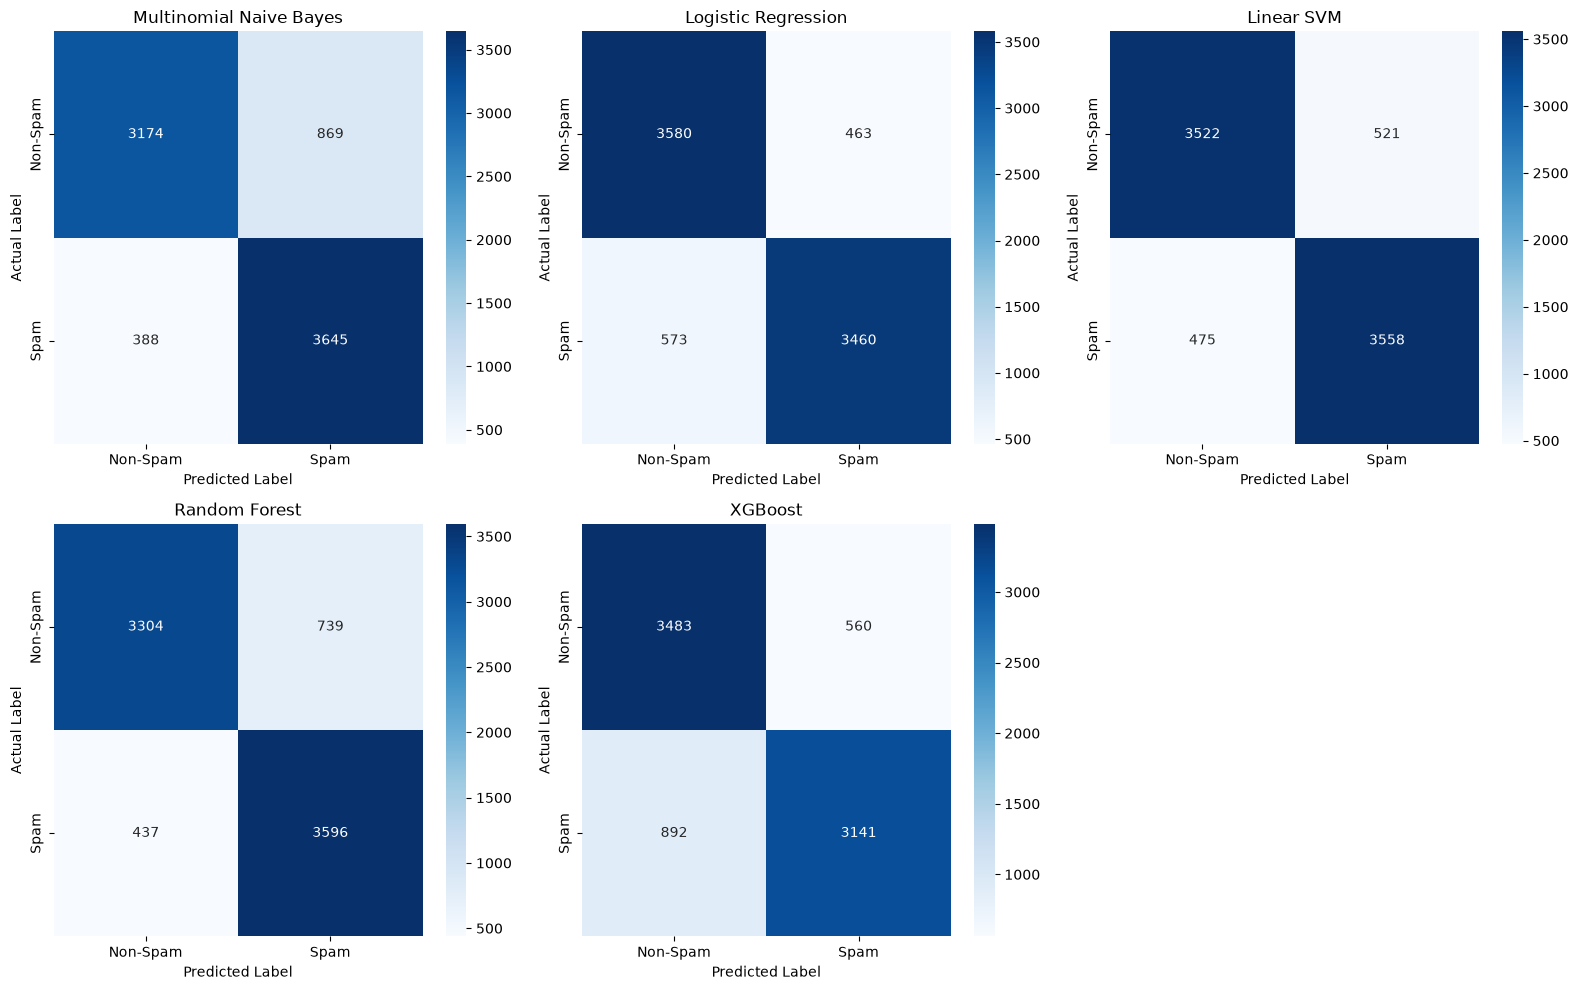

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrices for all five models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Spam", "Spam"],
        yticklabels=["Non-Spam", "Spam"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

# Hide unused subplot
axes[5].axis("off")

plt.tight_layout()
plt.show()

In [42]:
confusion_results = []

for name, y_pred in predictions.items():

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    confusion_results.append({
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_df = pd.DataFrame(confusion_results)

display(confusion_df.set_index("Model"))

,TN,FP,FN,TP
Model,,,,
Multinomial Naive Bayes,3174,869,388,3645
Logistic Regression,3580,463,573,3460
Linear SVM,3522,521,475,3558
Random Forest,3304,739,437,3596
XGBoost,3483,560,892,3141


**Finding:**

Linear SVM demonstrates a balanced classification performance, with 3,522 True Negatives and 3,558 True Positives. 

Logistic Regression achieves the highest True Negatives (3,580) and lowest False Positives (463), while Multinomial Naive Bayes achieves the highest True Positives (3,645). 

XGBoost produces the highest False Negatives (892), indicating that it misses more Spam reviews than the other models.

Overall, Linear SVM remains the strongest model based on the accuracy and F1-score comparison.

## Phase 6: Baseline Model Training Summary

| Step | Task | Result |
|---|---|---|
| 6.1 | Apply Unigram TF-IDF | Generated 33,022 features using training data only |
| 6.2 | Train Classification Models | Successfully trained five models |
| 6.3 | Evaluate Model Performance | Compared Accuracy, Precision, Recall, and F1-score |
| 6.4 | Confusion Matrix | Compared TN, FP, FN, and TP for all five models |

### Model Performance Comparison

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Multinomial Naive Bayes | 0.8444 | 0.8075 | 0.9038 | 0.8529 |
| Logistic Regression | 0.8717 | 0.8820 | 0.8579 | 0.8698 |
| Linear SVM | **0.8767** | 0.8723 | 0.8822 | **0.8772** |
| Random Forest | 0.8544 | 0.8295 | 0.8916 | 0.8595 |
| XGBoost | 0.8202 | 0.8487 | 0.7788 | 0.8123 |

### Conclusion

Linear SVM achieved the best overall baseline performance, with 87.67% accuracy and an 87.72% F1-score. Logistic Regression achieved the highest precision, while Multinomial Naive Bayes achieved the highest recall.

Therefore, Linear SVM is selected as the leading baseline model for further experiments. However, other models will also be considered when comparing feature extraction methods.

# Phase 7: Feature Extraction Comparison

The objective of this phase is to compare different text feature extraction methods and determine how they affect classification performance.

The three methods are:

1. Bag of Words (Unigram)
2. TF-IDF (Unigram)
3. TF-IDF (Unigram + Bigram)

Multinomial Naive Bayes, Logistic Regression, and Linear SVM will be used to compare the methods.

In [43]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize Bag of Words vectorizer
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 1)
)

# Fit and transform training data
X_train_bow = bow_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_bow = bow_vectorizer.transform(X_test)

# Display feature information
print("Training BoW Shape:", X_train_bow.shape)
print("Testing BoW Shape:", X_test_bow.shape)
print("Vocabulary Size:", len(bow_vectorizer.vocabulary_))

Training BoW Shape: (32302, 33022)
Testing BoW Shape: (8076, 33022)
Vocabulary Size: 33022


Bag of Words transformed the training and testing reviews into numerical feature matrices using 33,022 unigram features. The vectorizer was fitted only on training data and reused to transform testing data, preventing information leakage from the test set.

### Step 7.2: Apply TF-IDF (Unigram + Bigram)

Apply TF-IDF using unigrams and bigrams to capture individual words and short phrases in product reviews.

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF unigram + bigram vectorizer
tfidf_bigram_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2)
)

# Fit and transform training data
X_train_tfidf_bigram = tfidf_bigram_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_tfidf_bigram = tfidf_bigram_vectorizer.transform(X_test)

# Display feature information
print("Training TF-IDF Bigram Shape:", X_train_tfidf_bigram.shape)
print("Testing TF-IDF Bigram Shape:", X_test_tfidf_bigram.shape)
print("Vocabulary Size:", len(tfidf_bigram_vectorizer.vocabulary_))

Training TF-IDF Bigram Shape: (32302, 518484)
Testing TF-IDF Bigram Shape: (8076, 518484)
Vocabulary Size: 518484


### Step 7.3: Compare Feature Extraction Methods

Compare the vocabulary sizes and feature matrix dimensions of Bag of Words, TF-IDF Unigram, and TF-IDF Unigram + Bigram.

In [45]:
feature_comparison = pd.DataFrame({
    "Method": [
        "Bag of Words (Unigram)",
        "TF-IDF (Unigram)",
        "TF-IDF (Unigram + Bigram)"
    ],
    "Training Reviews": [
        X_train_bow.shape[0],
        X_train_tfidf.shape[0],
        X_train_tfidf_bigram.shape[0]
    ],
    "Testing Reviews": [
        X_test_bow.shape[0],
        X_test_tfidf.shape[0],
        X_test_tfidf_bigram.shape[0]
    ],
    "Vocabulary Size": [
        X_train_bow.shape[1],
        X_train_tfidf.shape[1],
        X_train_tfidf_bigram.shape[1]
    ]
})

display(feature_comparison)

,Method,Training Reviews,Testing Reviews,Vocabulary Size
0,Bag of Words (Unigram),32302,8076,33022
1,TF-IDF (Unigram),32302,8076,33022
2,TF-IDF (Unigram + Bigram),32302,8076,518484


Bag of Words and TF-IDF Unigram has the same vocabulary size of 33,022 features. However, TF-IDF Unigram + Bigram increased the vocabulary to 518,484 features by including two-word combinations. This provides richer phrase-level information but also increases computational requirements.

### Step 7.4: Train Models Using Different Feature Extraction Methods

Train five classification models using Bag of Words, TF-IDF Unigram, and TF-IDF Unigram + Bigram features.

The five models are:

1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear SVM
4. Random Forest
5. XGBoost

A total of 15 experiments will be conducted to compare the effects of different feature extraction methods on model performance.

In [47]:
# Recreate feature sets

feature_sets = {
    "BoW Unigram": (X_train_bow, X_test_bow),
    "TF-IDF Unigram": (X_train_tfidf, X_test_tfidf),
    "TF-IDF Unigram + Bigram": (X_train_tfidf_bigram, X_test_tfidf_bigram)
}

print("Feature sets are ready!")

for name, (X_train_features, X_test_features) in feature_sets.items():
    print(
        f"{name}: "
        f"Train {X_train_features.shape}, "
        f"Test {X_test_features.shape}"
    )

Feature sets are ready!
BoW Unigram: Train (32302, 33022), Test (8076, 33022)
TF-IDF Unigram: Train (32302, 33022), Test (8076, 33022)
TF-IDF Unigram + Bigram: Train (32302, 518484), Test (8076, 518484)


In [49]:
# Store predictions from the feature extraction experiments

feature_predictions = {}

print("feature_predictions initialized successfully!")

feature_predictions initialized successfully!


In [50]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Define all five models
models_to_train = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        max_iter=5000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Train only the six missing combinations
for feature_name, (X_train_features, X_test_features) in feature_sets.items():

    for model_name, model in models_to_train.items():

        key = (feature_name, model_name)

        # Skip the nine experiments already completed
        if key in feature_predictions:
            continue

        print(f"Training {feature_name} + {model_name}...")

        model.fit(X_train_features, y_train)

        feature_predictions[key] = model.predict(X_test_features)

        print("Completed!\n")

print("All experiments completed.")
print("Total experiments:", len(feature_predictions))

Training BoW Unigram + Multinomial Naive Bayes...
Completed!

Training BoW Unigram + Logistic Regression...
Completed!

Training BoW Unigram + Linear SVM...
Completed!

Training BoW Unigram + Random Forest...
Completed!

Training BoW Unigram + XGBoost...
Completed!

Training TF-IDF Unigram + Multinomial Naive Bayes...
Completed!

Training TF-IDF Unigram + Logistic Regression...
Completed!

Training TF-IDF Unigram + Linear SVM...
Completed!

Training TF-IDF Unigram + Random Forest...
Completed!

Training TF-IDF Unigram + XGBoost...
Completed!

Training TF-IDF Unigram + Bigram + Multinomial Naive Bayes...
Completed!

Training TF-IDF Unigram + Bigram + Logistic Regression...
Completed!

Training TF-IDF Unigram + Bigram + Linear SVM...
Completed!

Training TF-IDF Unigram + Bigram + Random Forest...
Completed!

Training TF-IDF Unigram + Bigram + XGBoost...
Completed!

All experiments completed.
Total experiments: 15


All 15 experiments were successfully completed using five classification algorithms and three feature extraction methods. Each model generated predictions on the same testing dataset of 8,076 reviews, allowing a consistent performance comparison.

### Step 7.5: Evaluate Feature Extraction and Model Performance

Evaluate all 15 experiments using Accuracy, Precision, Recall, and F1-score to identify the best combination of feature extraction method and classification algorithm.

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

feature_results = []

for (feature_name, model_name), y_pred in feature_predictions.items():

    feature_results.append({
        "Feature Extraction": feature_name,
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

# Create comparison table
feature_results_df = pd.DataFrame(feature_results)

# Display all results
display(
    feature_results_df.round(4)
)

,Feature Extraction,Model,Accuracy,Precision,Recall,F1-Score
0,BoW Unigram,Multinomial Naive Bayes,0.8336,0.8015,0.8862,0.8417
1,BoW Unigram,Logistic Regression,0.8741,0.8657,0.8852,0.8753
2,BoW Unigram,Linear SVM,0.8606,0.8435,0.8849,0.8637
3,BoW Unigram,Random Forest,0.8489,0.8119,0.9078,0.8572
4,BoW Unigram,XGBoost,0.8039,0.8300,0.7637,0.7955
5,TF-IDF Unigram,Multinomial Naive Bayes,0.8444,0.8075,0.9038,0.8529
6,TF-IDF Unigram,Logistic Regression,0.8717,0.8820,0.8579,0.8698
7,TF-IDF Unigram,Linear SVM,0.8767,0.8723,0.8822,0.8772
8,TF-IDF Unigram,Random Forest,0.8544,0.8295,0.8916,0.8595
9,TF-IDF Unigram,XGBoost,0.8202,0.8487,0.7788,0.8123


### Step 7.6: Visualize Model Performance

Visualize the F1-scores of all five classification models across the three feature extraction methods using a grouped bar chart. This comparison helps identify which combination achieves the best classification performance.

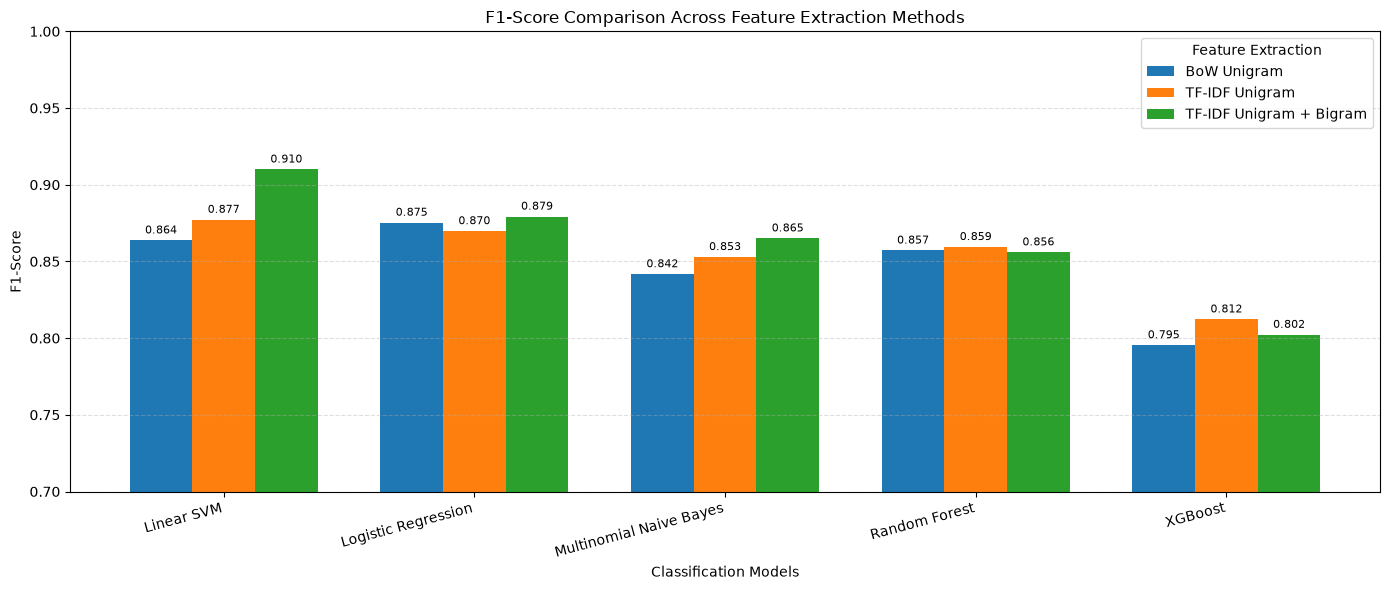

In [53]:
# Prepare F1-score data
f1_pivot = feature_results_df.pivot(
    index="Model",
    columns="Feature Extraction",
    values="F1-Score"
)

# Set chart positions
x = np.arange(len(f1_pivot.index))
width = 0.25

# Create grouped bar chart
plt.figure(figsize=(14, 6))

for i, feature in enumerate(f1_pivot.columns):
    bars = plt.bar(
        x + (i - 1) * width,
        f1_pivot[feature],
        width,
        label=feature
    )

    # Add F1-score labels
    plt.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

# Chart formatting
plt.title("F1-Score Comparison Across Feature Extraction Methods")
plt.xlabel("Classification Models")
plt.ylabel("F1-Score")
plt.xticks(x, f1_pivot.index, rotation=15, ha="right")
plt.ylim(0.70, 1.00)
plt.legend(title="Feature Extraction")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [54]:
# Sort results by Accuracy in descending order
accuracy_results_df = feature_results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display sorted results
display(
    accuracy_results_df.round(4)
)

,Feature Extraction,Model,Accuracy,Precision,Recall,F1-Score
0,TF-IDF Unigram + Bigram,Linear SVM,0.9107,0.9163,0.9038,0.9100
1,TF-IDF Unigram + Bigram,Logistic Regression,0.8811,0.8921,0.8668,0.8793
2,TF-IDF Unigram,Linear SVM,0.8767,0.8723,0.8822,0.8772
3,BoW Unigram,Logistic Regression,0.8741,0.8657,0.8852,0.8753
4,TF-IDF Unigram,Logistic Regression,0.8717,0.8820,0.8579,0.8698
5,BoW Unigram,Linear SVM,0.8606,0.8435,0.8849,0.8637
6,TF-IDF Unigram,Random Forest,0.8544,0.8295,0.8916,0.8595
7,TF-IDF Unigram + Bigram,Multinomial Naive Bayes,0.8520,0.7942,0.9499,0.8651
8,BoW Unigram,Random Forest,0.8489,0.8119,0.9078,0.8572
9,TF-IDF Unigram + Bigram,Random Forest,0.8465,0.8051,0.9137,0.8560


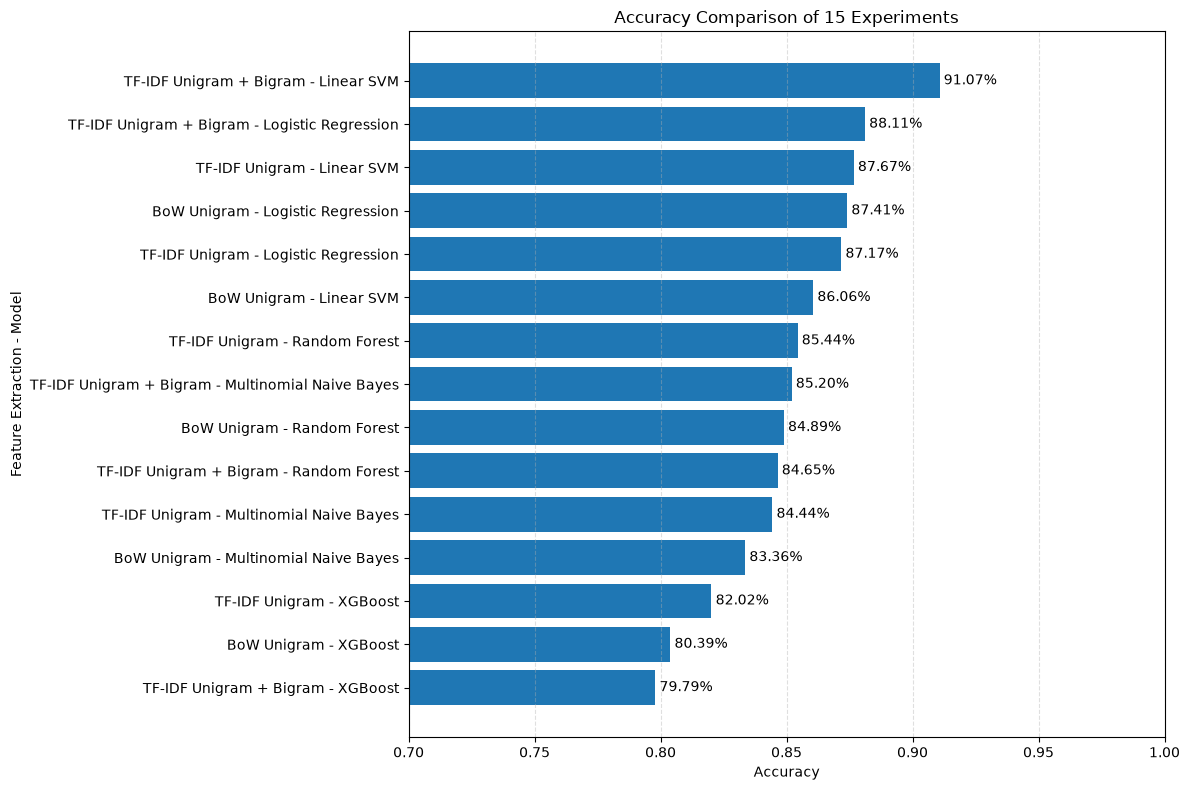

In [55]:
# Sort results by accuracy
accuracy_results_df = feature_results_df.sort_values(
    by="Accuracy",
    ascending=True
)

# Create model labels
labels = (
    accuracy_results_df["Feature Extraction"]
    + " - "
    + accuracy_results_df["Model"]
)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

bars = plt.barh(
    labels,
    accuracy_results_df["Accuracy"]
)

# Add accuracy labels
plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=3,
    labels=[
        f"{value * 100:.2f}%"
        for value in accuracy_results_df["Accuracy"]
    ]
)

plt.title("Accuracy Comparison of 15 Experiments")
plt.xlabel("Accuracy")
plt.ylabel("Feature Extraction - Model")
plt.xlim(0.70, 1.00)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Finding:**

TF-IDF Unigram + Bigram with Linear SVM achieved the highest accuracy of 91.07%, followed by TF-IDF Unigram + Bigram with Logistic Regression at 88.11%.

Among the five algorithms, Linear SVM and Logistic Regression generally achieved stronger accuracy across the feature extraction methods. Multinomial Naive Bayes achieved the highest recall (94.99%) with TF-IDF Unigram + Bigram, but its accuracy was 85.20%.

XGBoost recorded the lowest accuracy across all three feature extraction methods.

Overall, TF-IDF Unigram + Bigram combined with Linear SVM is the best-performing combination based on accuracy and F1-score.

# Phase 8: Model Validation and Cross-Validation

The objective of this phase is to evaluate the reliability and consistency of the best-performing model from the previous experiments.

The selected combination is **TF-IDF Unigram + Bigram with Linear SVM**, which achieved 91.07% accuracy.

Five-fold Stratified Cross-Validation will be used to evaluate model performance across different training and validation splits while maintaining the class distribution.

In [56]:
# Import required libraries
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.svm import LinearSVC
# from sklearn.model_selection import StratifiedKFold, cross_validate
# import pandas as pd

# Initialize TF-IDF Unigram + Bigram
cv_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2)
)

# Fit vectorizer using training data only
X_train_cv = cv_vectorizer.fit_transform(X_train)

# Initialize Linear SVM
best_model = LinearSVC(
    max_iter=5000,
    random_state=42
)

# Display preparation information
print("Training Data Shape:", X_train_cv.shape)
print("Vocabulary Size:", len(cv_vectorizer.vocabulary_))
print("Selected Model:", "Linear SVM")
print("Feature Extraction:", "TF-IDF Unigram + Bigram")

Training Data Shape: (32302, 518484)
Vocabulary Size: 518484
Selected Model: Linear SVM
Feature Extraction: TF-IDF Unigram + Bigram


### Step 8.2: Perform 5-Fold Stratified Cross-Validation

Apply 5-Fold Stratified Cross-Validation to evaluate the selected Linear SVM model. The training dataset will be divided into five folds, with each fold used once for validation while the remaining four folds are used for training.

Accuracy, precision, recall, and F1-score will be recorded for each fold.

In [57]:
# Initialize 5-fold stratified cross-validation
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Perform cross-validation
cv_results = cross_validate(
    best_model,
    X_train_cv,
    y_train,
    cv=stratified_cv,
    scoring=scoring,
    n_jobs=-1
)

# Display results for each fold
cv_results_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1-Score": cv_results["test_f1"]
})

display(cv_results_df.round(4))

,Fold,Accuracy,Precision,Recall,F1-Score
0,1,0.9064,0.9265,0.8825,0.9040
1,2,0.9138,0.9345,0.8896,0.9115
2,3,0.9116,0.9362,0.8831,0.9089
3,4,0.9169,0.9364,0.8943,0.9149
4,5,0.9099,0.9377,0.8779,0.9068


### Step 8.2: Perform Leakage-Free 5-Fold Stratified Cross-Validation

Use a machine learning Pipeline to combine TF-IDF Unigram + Bigram feature extraction with Linear SVM.

The Pipeline ensures that TF-IDF is fitted only on the training portion of each fold, preventing information leakage into the validation portion.

Evaluate the model using Accuracy, Precision, Recall, and F1-score across five stratified folds.

Each fold now gets its own TF-IDF vocabulary and IDF weights, calculated exclusively from that fold's training portion.

In [59]:
# Create TF-IDF and Linear SVM pipeline
cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("svm", LinearSVC(max_iter=5000, random_state=42))
])

# Initialize 5-fold stratified cross-validation
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Perform cross-validation on raw training text
cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=scoring,
    n_jobs=1
)

# Display results
cv_results_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1-Score": cv_results["test_f1"]
})

display(cv_results_df.round(4))

,Fold,Accuracy,Precision,Recall,F1-Score
0,1,0.9002,0.9047,0.8943,0.8995
1,2,0.9119,0.9168,0.9058,0.9113
2,3,0.9098,0.9170,0.9008,0.9088
3,4,0.9141,0.9183,0.9089,0.9135
4,5,0.9043,0.9142,0.8921,0.9030


### Step 8.3: Calculate Average Cross-Validation Performance

Calculate the average and standard deviation of Accuracy, Precision, Recall, and F1-score across the five validation folds.

The average represents the overall performance, while the standard deviation indicates how much the results vary between folds.

In [60]:
# Calculate average and standard deviation
cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ],
    "Standard Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std()
    ]
})

# Display summary
display(cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.9081,0.0051
1,Precision,0.9142,0.0049
2,Recall,0.9004,0.0064
3,F1-Score,0.9072,0.0052


- Accuracy: The model correctly classifies approximately 90.81% of validation reviews on average.
- Precision: 91.42% of reviews predicted as Spam are actually Spam.
- Recall: The model identifies approximately 90.04% of actual Spam reviews.
- F1-score: The model achieves a balanced F1-score of 90.72%.
- Standard deviation: All four metrics have relatively small variation across folds, indicating consistent performance.

**Finding:**

The TF-IDF Unigram + Bigram with Linear SVM achieved an average accuracy of 90.81% and an F1-score of 90.72% across five-fold Stratified Cross-Validation. The average precision was 91.42%, while recall was 90.04%.

The standard deviations across all evaluation metrics were relatively small, ranging from 0.0049 to 0.0064. This indicates that the model maintained consistent performance across the five validation folds.

Overall, the cross-validation results support the model's reliability and suggest that its performance is not dependent on a single training and validation split.

### Step 8.4: Final Model Evaluation

Train the selected TF-IDF Unigram + Bigram and Linear SVM Pipeline using the complete training dataset.

Evaluate the trained model on the separate testing dataset using Accuracy, Precision, Recall, and F1-score.

This provides the final performance measurement on unseen reviews.

In [61]:
# Train the Pipeline using the complete training dataset
cv_pipeline.fit(X_train, y_train)

# Predict labels for the testing dataset
y_pred_final = cv_pipeline.predict(X_test)

# Calculate final evaluation metrics
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score": [
        accuracy_score(y_test, y_pred_final),
        precision_score(y_test, y_pred_final),
        recall_score(y_test, y_pred_final),
        f1_score(y_test, y_pred_final)
    ]
})

# Display final results
display(final_results.round(4))

,Metric,Score
0,Accuracy,0.9107
1,Precision,0.9163
2,Recall,0.9038
3,F1-Score,0.9100


**Finding:**

The final Linear SVM model using TF-IDF Unigram + Bigram achieved 91.07% accuracy, 91.63% precision, 90.38% recall, and a 91.00% F1-score on the testing dataset.

The final test results are close to the five-fold cross-validation averages, with differences of less than 0.35 percentage points across all evaluation metrics. This indicates that the model maintains consistent performance across validation folds and the separate testing dataset.

Overall, the selected model demonstrates strong classification performance in distinguishing computer-generated reviews from original reviews in this dataset.

### Step 8.5: Final Confusion Matrix

Generate a confusion matrix to examine the final model's classification results. The matrix will show the number of correctly and incorrectly classified Spam and Non-Spam reviews.

Confusion Matrix
----------------
True Negative (TN):  3710
False Positive (FP): 333
False Negative (FN): 388
True Positive (TP):  3645


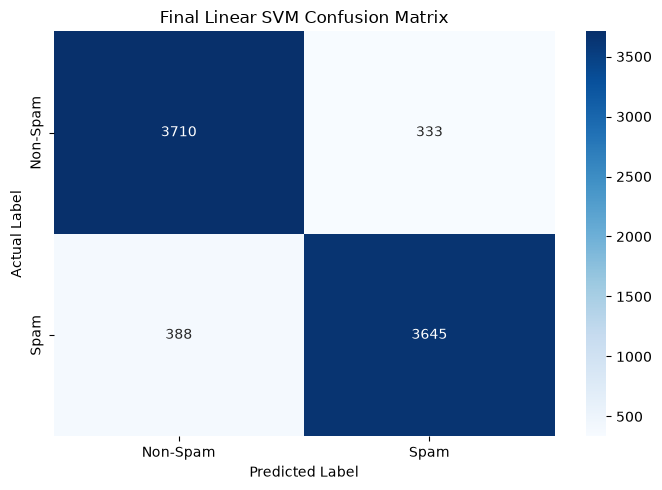

In [63]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred_final)

# Extract TN, FP, FN, and TP
tn, fp, fn, tp = cm.ravel()

# Display confusion matrix values
print("Confusion Matrix")
print("----------------")
print(f"True Negative (TN):  {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative (FN): {fn}")
print(f"True Positive (TP):  {tp}")

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Spam", "Spam"],
    yticklabels=["Non-Spam", "Spam"]
)

plt.title("Final Linear SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


**Finding:**

The final Linear SVM model correctly classified 3,710 Non-Spam reviews and 3,645 Spam reviews. It produced 333 False Positives and 388 False Negatives.

The number of False Positives was lower than the number of False Negatives, indicating that the model was slightly more likely to miss computer-generated reviews than incorrectly classify original reviews as Spam.

Overall, the confusion matrix demonstrates that the model can distinguish between the two review classes with relatively few classification errors.

## Phase 8: Model Validation and Cross-Validation Summary

| Step | Task | Result |
|---|---|---|
| 8.1 | Prepare the Best Model | Selected TF-IDF Unigram + Bigram with Linear SVM |
| 8.2 | 5-Fold Stratified Cross-Validation | Evaluated model across five folds using a Pipeline |
| 8.3 | Calculate Average Performance | Accuracy: 90.81%, F1-score: 90.72% |
| 8.4 | Final Model Evaluation | Test accuracy: 91.07%, F1-score: 91.00% |
| 8.5 | Confusion Matrix | TN: 3,710, FP: 333, FN: 388, TP: 3,645 |

### Cross-Validation Results

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Accuracy | 0.9081 | 0.0051 |
| Precision | 0.9142 | 0.0049 |
| Recall | 0.9004 | 0.0064 |
| F1-Score | 0.9072 | 0.0052 |

### Final Test Results

| Metric | Score |
|---|---:|
| Accuracy | 0.9107 |
| Precision | 0.9163 |
| Recall | 0.9038 |
| F1-Score | 0.9100 |

### Conclusion

The selected TF-IDF Unigram + Bigram with Linear SVM achieved 91.07% accuracy and a 91.00% F1-score on the testing dataset. Five-fold Stratified Cross-Validation produced similar average performance, indicating consistent results across different data splits.

The confusion matrix also showed relatively few classification errors, with 333 False Positives and 388 False Negatives.

Therefore, Linear SVM with TF-IDF Unigram + Bigram is selected as the final model for this project.


# Phase 9: Model Interpretation and Error Analysis

## Objective

Interpret the final Linear SVM model by identifying important text features and examining incorrectly classified reviews.

This phase focuses on understanding which words and phrases influence the model's predictions and identifying possible reasons for classification errors.


### Step 9.1: Identify Important Features

Linear SVM uses learned coefficients to determine how strongly each feature contributes to a prediction.

- Positive coefficients indicate features associated with Spam (1).
- Negative coefficients indicate features associated with Non-Spam (0).
- Larger absolute coefficient values indicate stronger influence on the model's decision.

We will extract the coefficients from the trained Linear SVM model and identify the top 20 features for each class.


In [69]:

# Extract the trained SVM model and TF-IDF feature names

svm_model = cv_pipeline.named_steps["svm"]

feature_names = cv_pipeline.named_steps["tfidf"].get_feature_names_out()

# Extract model coefficients

coefficients = svm_model.coef_[0]

# Create a feature importance DataFrame

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort features by coefficient

top_spam_features = (
    feature_importance
    .sort_values(by="Coefficient", ascending=False)
    .head(20)
)

top_non_spam_features = (
    feature_importance
    .sort_values(by="Coefficient", ascending=True)
    .head(20)
)

print("Top 20 Features Associated with Spam:")
display(top_spam_features)

print("Top 20 Features Associated with Non-Spam:")
display(top_non_spam_features)


Top 20 Features Associated with Spam:


,Feature,Coefficient
367938,reason,3.732207
127470,downside,3.469659
13166,admit,3.469599
503077,wide,3.314119
368033,reason gave,3.090095
349408,problem,3.044459
374697,replace,2.868709
102027,couple,2.843280
19083,also love,2.832142
307214,not sure,2.768975


Top 20 Features Associated with Non-Spam:


,Feature,Coefficient
144625,even,-3.078382
456176,though,-2.705133
302811,no,-2.527784
505867,without,-2.396778
23487,another,-2.214572
10990,actually,-2.197354
216181,however,-2.187256
292476,much,-2.095859
138452,end,-1.914820
133326,easily,-1.910457


**Finding:**

The Linear SVM model identified different textual features associated with Spam and Non-Spam reviews. Features such as "reason", "downside", and "problem" had strong positive coefficients, indicating an association with Spam reviews. In contrast, features such as "even", "though", and "without" had strong negative coefficients, indicating an association with Non-Spam reviews.

These results show that the model uses individual words and word combinations to distinguish between the two classes. However, these features represent patterns learned from this dataset and should not be treated as universal indicators of fake or original reviews.

### Step 9.2: Inspect Misclassified Reviews

Examine reviews that the final Linear SVM model incorrectly classified.

Compare the original review text, actual labels, and predicted labels to identify two types of classification errors:

- **False Positive (FP):** A Non-Spam review incorrectly predicted as Spam.
- **False Negative (FN):** A Spam review incorrectly predicted as Non-Spam.

This analysis helps us understand the types of reviews that the model struggles to classify correctly.


In [72]:
print("Test dataset size:", len(X_test))
print("Actual labels size:", len(y_test))
print("Predicted labels size:", len(y_pred_final))

print("\nTest dataset index sample:")
print(X_test.index[:10])


Test dataset size: 8076
Actual labels size: 8076
Predicted labels size: 8076

Test dataset index sample:
Index([230, 13418, 13919, 19527, 23418, 5645, 7946, 11917, 34195, 6614], dtype='int64')


In [ ]:
# Generate predictions using the final model
y_pred_final = cv_pipeline.predict(X_test)

# Create a DataFrame containing prediction results
error_analysis = pd.DataFrame({
    "Original Review": test_dataset["text_"].values,
    "Actual": np.asarray(y_test),
    "Predicted": y_pred_final
})

# Select incorrectly classified reviews
misclassified_reviews = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
].copy()

# Identify classification error types
misclassified_reviews["Error Type"] = np.where(
    misclassified_reviews["Actual"] == 0,
    "False Positive",
    "False Negative"
)

# Convert numerical labels into readable names
misclassified_reviews["Actual"] = misclassified_reviews["Actual"].map({
    0: "Non-Spam",
    1: "Spam"
})

misclassified_reviews["Predicted"] = misclassified_reviews["Predicted"].map({
    0: "Non-Spam",
    1: "Spam"
})

print("Total misclassified reviews:", len(misclassified_reviews))

display(misclassified_reviews.head(10))


Total misclassified reviews: 721


,Original Review,Actual,Predicted,Error Type
0,Great comforter especially when you are on the go. I will keep my shelves in order,Spam,Non-Spam,False Negative
22,This was a very nice book to read. I read it to a small group of adult for a literacy project an everyone loves it.\n\nSo inconclusion i liked this book.,Non-Spam,Spam,False Positive
32,wonderfully written. Vivid description and a sweet love story.\n\nI received this book in,Spam,Non-Spam,False Negative
34,Love it. Cleans easily. Love it. Love it.,Spam,Non-Spam,False Negative
39,"Was difficult to read, at times. TMI. Anyone who likes fashion/designers could find it interesting. History of department stores is included",Non-Spam,Spam,False Positive
40,Warm incandescent-like light. Dims as low as the strobe setting but it,Spam,Non-Spam,False Negative
66,all I can say is I love this movie it great you will love it...,Non-Spam,Spam,False Positive
82,"Well, this device definitely works better than the stock Garmin. I did not need a GPS to find the street and I had no need for a GPS to find the street. The only other thing I needed was to find the street in a particular location. This was easy to do and I would recommend it to anyone looking to do it. I had to return it because the product was defective.",Spam,Non-Spam,False Negative
95,I don't no who don't know what the movie is about but it's kind of a slow,Spam,Non-Spam,False Negative
99,"I used this fish tape measure to measure the thickness of the fish. The thickness was measured by measuring the thickness of the plastic, which is then measured by measuring the thickness of the metal.",Spam,Non-Spam,False Negative


#### Misclassification Analysis

The Linear SVM model incorrectly classified 721 reviews, consisting of 333 False Positives and 388 False Negatives.

The inspected examples show that some Spam reviews contain natural-sounding language and ordinary product descriptions, causing the model to classify them as Non-Spam. Meanwhile, some genuine reviews contain unusual wording or language patterns that the model associates with Spam.

These errors indicate that Spam and Non-Spam reviews can share similar linguistic characteristics, making accurate classification challenging.


Overall, the analysis shows that the model can distinguish between many Spam and Non-Spam reviews, but some reviews share similar linguistic patterns, resulting in incorrect predictions.
